# Analisis Data: [Adjusment Bike Sharing Dataset]
- **Nama:** Muhamad Agung Somomiharjo
- **Email:** magungsomomiharjo@gmail.com
- **ID Dicoding:** ds128b6y1057

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Berdasarkan data penyewaan 3–6 bulan terakhir, pada hari dan rentang jam berapa saja tingkat keterisian slot lapangan mencapai angka tertinggi dan terendah, serta bagaimana perbedaannya pada akhir pekan dan hari libur nasional dibandingkan hari kerja?

- **Pertanyaan 2:** Selama periode 3–6 bulan terakhir, berapa proporsi pemesanan untuk kegiatan futsal rutin dibandingkan dengan penyewaan acara atau gedung serbaguna berdasarkan hari dan jamnya?

- **Pertanyaan 3:** 

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import seaborn as sns
import holidays as hol
import numpy as np
import matplotlib.pyplot as plt

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
day_df = pd.read_csv('data/day.csv')

# 5 data pertama di DataFrame dari day_df dan hour_df
print(f"Day DataFrame:\n {day_df.head()}\n")

Day DataFrame:
    instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  



### Assessing Data

#### Identifying ... problem

In [3]:
print(f"Info table day_df:\n")
print(day_df.info())

Info table day_df:

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB
None


In [4]:
print(f"Descriptive Statistics table day_df: \n {day_df.describe()}\n")

Descriptive Statistics table day_df: 
           instant      season          yr        mnth     holiday     weekday  \
count  731.000000  731.000000  731.000000  731.000000  731.000000  731.000000   
mean   366.000000    2.496580    0.500684    6.519836    0.028728    2.997264   
std    211.165812    1.110807    0.500342    3.451913    0.167155    2.004787   
min      1.000000    1.000000    0.000000    1.000000    0.000000    0.000000   
25%    183.500000    2.000000    0.000000    4.000000    0.000000    1.000000   
50%    366.000000    3.000000    1.000000    7.000000    0.000000    3.000000   
75%    548.500000    3.000000    1.000000   10.000000    0.000000    5.000000   
max    731.000000    4.000000    1.000000   12.000000    1.000000    6.000000   

       workingday  weathersit        temp       atemp         hum   windspeed  \
count  731.000000  731.000000  731.000000  731.000000  731.000000  731.000000   
mean     0.683995    1.395349    0.495385    0.474354    0.627894    

In [5]:
# Mengecek missing values di day_df
print(f"Missing values di day_df: \n {day_df.isna().sum()}\n")

Missing values di day_df: 
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64



In [6]:
# Mengecek duplicate values di day_df
print(f"Duplicate values di day_df: \n {day_df.duplicated().sum()}\n")

Duplicate values di day_df: 
 0



In [7]:
print(day_df.dtypes)

instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


**Insight:** Pada Table day.csv tidak ditemukan masalah missing_value, duplicate_value. Namun terdapat satu masalah yaitu invalid_data_type pada kolom `dteday` yang seharusnya bertipe `datetime`.

**Steps to Take:**
1. Ubah tipe data pada kolom `dteday` menjadi `datetime`

### Cleaning Data

#### Fixing invalid_data_type problem

In [8]:
# Ngubah kolom dteday yang sebelumnya string menjadi tipe data datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

In [9]:
# cek hasil konversi tipe data dteday
print(f"Tipe data dteday di day_df: {day_df['dteday'].dtype}\n")

Tipe data dteday di day_df: datetime64[us]



#### Feature Engineering

In [10]:
"""
    Detail mengenai Feature Engineering ada pada Data/data/adjusment_tbl_day.txt
"""

# Ngapus kolom yang ga perlu di day_df
adjusment_day_df = day_df.drop(['weathersit', 'temp', 'workingday', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'], axis=1)

# Mengganti kolom (yr) dan ganti range kolom (dteday) jadi 2024-2025 pada dataset (day.csv):
adjusment_day_df['dteday'] = pd.date_range(start='2024-01-01', periods=len(day_df), freq='D')
adjusment_day_df['mnth'] = adjusment_day_df['dteday'].dt.month
adjusment_day_df['yr'] = adjusment_day_df['dteday'].dt.year - 2024

# Ambil tahun yang tersedia di DataFrame
years = adjusment_day_df["dteday"].dt.year.unique()

# Daftar hari libur nasional Indonesia
hari_libur_indonesia = hol.Indonesia(years=years)

# Ubah menjadi 1 jika hari libur nasional, 0 jika bukan
adjusment_day_df["holiday"] = adjusment_day_df["dteday"].apply(
    lambda tanggal: int(tanggal.date() in hari_libur_indonesia)
)

# ganti musmim
rainy_season_mnth = [5, 6, 7, 8, 9, 10]  # Mei hingga Oktober
adjusment_day_df["season"] = adjusment_day_df["mnth"].apply(
    lambda bulan: "Musim Hujan" if bulan in rainy_season_mnth else "Musim Kemarau"
)

# ganti nama kolom musim
adjusment_day_df['musim'] = adjusment_day_df['season']

# nambahin datetype
adjusment_day_df["date_type"] = adjusment_day_df["holiday"].apply(   
    lambda is_holiday: "Holiday" if is_holiday == 1 else "Working Day"
)

In [11]:
adjusment_day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   instant    731 non-null    int64         
 1   dteday     731 non-null    datetime64[us]
 2   season     731 non-null    str           
 3   yr         731 non-null    int32         
 4   mnth       731 non-null    int32         
 5   holiday    731 non-null    int64         
 6   weekday    731 non-null    int64         
 7   musim      731 non-null    str           
 8   date_type  731 non-null    str           
dtypes: datetime64[us](1), int32(2), int64(3), str(3)
memory usage: 45.8 KB


In [12]:
adjusment_day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,musim,date_type
0,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday
1,2,2024-01-02,Musim Kemarau,0,1,0,0,Musim Kemarau,Working Day
2,3,2024-01-03,Musim Kemarau,0,1,0,1,Musim Kemarau,Working Day
3,4,2024-01-04,Musim Kemarau,0,1,0,2,Musim Kemarau,Working Day
4,5,2024-01-05,Musim Kemarau,0,1,0,3,Musim Kemarau,Working Day


In [13]:
print(adjusment_day_df.dtypes)

instant               int64
dteday       datetime64[us]
season                  str
yr                    int32
mnth                  int32
holiday               int64
weekday               int64
musim                   str
date_type               str
dtype: object


In [14]:
adjusment_day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,musim,date_type
0,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday
1,2,2024-01-02,Musim Kemarau,0,1,0,0,Musim Kemarau,Working Day
2,3,2024-01-03,Musim Kemarau,0,1,0,1,Musim Kemarau,Working Day
3,4,2024-01-04,Musim Kemarau,0,1,0,2,Musim Kemarau,Working Day
4,5,2024-01-05,Musim Kemarau,0,1,0,3,Musim Kemarau,Working Day


In [15]:
# liat 15 data terakhir di DataFrame dari adjusment_day_df
adjusment_day_df.tail()

,instant,dteday,season,yr,mnth,holiday,weekday,musim,date_type
726,727,2025-12-27,Musim Kemarau,1,12,0,4,Musim Kemarau,Working Day
727,728,2025-12-28,Musim Kemarau,1,12,0,5,Musim Kemarau,Working Day
728,729,2025-12-29,Musim Kemarau,1,12,0,6,Musim Kemarau,Working Day
729,730,2025-12-30,Musim Kemarau,1,12,0,0,Musim Kemarau,Working Day
730,731,2025-12-31,Musim Kemarau,1,12,0,1,Musim Kemarau,Working Day


In [16]:
# Daftar slot yang ingin dijadikan baris
slot_hours = range(6, 24)  # 06:00 sampai 00:00
slots_df = pd.DataFrame({
    "slot_jam": slot_hours
})

slots_df["jam_mulai"] = slots_df["slot_jam"].astype(str).str.zfill(2) + ":00"
slots_df["jam_selesai"] = (slots_df["slot_jam"] + 1).astype(str).str.zfill(2) + ":00"

In [17]:
slots_df.head(20)

,slot_jam,jam_mulai,jam_selesai
0,6,06:00,07:00
1,7,07:00,08:00
2,8,08:00,09:00
3,9,09:00,10:00
4,10,10:00,11:00
5,11,11:00,12:00
6,12,12:00,13:00
7,13,13:00,14:00
8,14,14:00,15:00
9,15,15:00,16:00


In [18]:
slots_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   slot_jam     18 non-null     int64
 1   jam_mulai    18 non-null     str  
 2   jam_selesai  18 non-null     str  
dtypes: int64(1), str(2)
memory usage: 564.0 bytes


In [19]:
# Cross join: setiap tanggal dikalikan seluruh slot
adjusment_hour_df = (
    adjusment_day_df.assign(key=1)
    .merge(slots_df.assign(key=1), on="key")
    .drop(columns="key")
)

In [20]:
adjusment_hour_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,musim,date_type,slot_jam,jam_mulai,jam_selesai
0,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,6,06:00,07:00
1,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,7,07:00,08:00
2,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,8,08:00,09:00
3,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,9,09:00,10:00
4,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,10,10:00,11:00


In [21]:
adjusment_hour_df.tail()

,instant,dteday,season,yr,mnth,holiday,weekday,musim,date_type,slot_jam,jam_mulai,jam_selesai
13153,731,2025-12-31,Musim Kemarau,1,12,0,1,Musim Kemarau,Working Day,19,19:00,20:00
13154,731,2025-12-31,Musim Kemarau,1,12,0,1,Musim Kemarau,Working Day,20,20:00,21:00
13155,731,2025-12-31,Musim Kemarau,1,12,0,1,Musim Kemarau,Working Day,21,21:00,22:00
13156,731,2025-12-31,Musim Kemarau,1,12,0,1,Musim Kemarau,Working Day,22,22:00,23:00
13157,731,2025-12-31,Musim Kemarau,1,12,0,1,Musim Kemarau,Working Day,23,23:00,24:00


In [22]:
nama_hari = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu"
}

# Nambahin kolom tanggal, hari, is_weekend, dan is_libur_nasional
adjusment_hour_df["tanggal"] = adjusment_hour_df["dteday"].dt.strftime("%Y-%m-%d")

adjusment_hour_df["hari"] = (
    adjusment_hour_df["dteday"].dt.dayofweek.map(nama_hari)
)

adjusment_hour_df["is_weekend"] = (
    adjusment_hour_df["dteday"].dt.dayofweek >= 5
).astype(int)

adjusment_hour_df["is_libur_nasional"] = (
    adjusment_hour_df["holiday"].fillna(0).astype(int)
)

In [23]:
rng = np.random.default_rng(42)

# Baseline untuk hari reguler (futsal): ~35% slot terisi secara acak
adjusment_hour_df["status_terisi"] = rng.choice(
    [0, 1],
    size=len(adjusment_hour_df),
    p=[0.65, 0.35]
)

adjusment_hour_df["jumlah_booking"] = (
    adjusment_hour_df["status_terisi"]
)

adjusment_hour_df["jenis_penggunaan"] = "futsal"

# Simulasi kemunculan "acara": 1-2x per 1-3 bulan, berdurasi 1-5 hari berturutan
min_tgl = adjusment_hour_df["dteday"].min()
max_tgl = adjusment_hour_df["dteday"].max()

tanggal_acara = set()
periode_mulai = min_tgl

while periode_mulai <= max_tgl:
    panjang_bulan = int(rng.integers(1, 4))  # 1-3 bulan
    periode_selesai = min(
        periode_mulai + pd.DateOffset(months=panjang_bulan) - pd.Timedelta(days=1),
        max_tgl
    )
    jumlah_acara = int(rng.integers(1, 3))  # 1-2x per periode

    kandidat_hari = pd.date_range(periode_mulai, periode_selesai, freq="D")
    terpilih = 0
    percobaan = 0
    while terpilih < jumlah_acara and percobaan < 30 and len(kandidat_hari) > 0:
        percobaan += 1
        mulai_acara = pd.Timestamp(rng.choice(kandidat_hari))
        durasi_hari = int(rng.integers(1, 6))  # 1-5 hari berturutan
        selesai_acara = min(mulai_acara + pd.Timedelta(days=durasi_hari - 1), max_tgl)

        blok_acara = pd.date_range(mulai_acara, selesai_acara, freq="D")
        # Buffer 1 hari sebelum & sesudah agar antar-acara tidak menyatu
        blok_buffer = pd.date_range(
            max(mulai_acara - pd.Timedelta(days=1), min_tgl),
            min(selesai_acara + pd.Timedelta(days=1), max_tgl),
            freq="D"
        )

        if not any(tgl in tanggal_acara for tgl in blok_buffer):
            tanggal_acara.update(blok_acara)
            terpilih += 1

    periode_mulai = periode_selesai + pd.Timedelta(days=1)

# Pada hari-hari acara, semua slot jam = "acara" + full booking
mask_acara = adjusment_hour_df["dteday"].isin(tanggal_acara)
adjusment_hour_df.loc[mask_acara, "jenis_penggunaan"] = "acara"
adjusment_hour_df.loc[mask_acara, "status_terisi"] = 1
adjusment_hour_df.loc[mask_acara, "jumlah_booking"] = 1

adjusment_hour_df["sumber_data"] = "dummy_simulasi"

In [24]:
adjusment_hour_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,musim,date_type,slot_jam,jam_mulai,jam_selesai,tanggal,hari,is_weekend,is_libur_nasional,status_terisi,jumlah_booking,jenis_penggunaan,sumber_data
0,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,6,06:00,07:00,2024-01-01,Senin,0,1,1,1,futsal,dummy_simulasi
1,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,7,07:00,08:00,2024-01-01,Senin,0,1,0,0,futsal,dummy_simulasi
2,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,8,08:00,09:00,2024-01-01,Senin,0,1,1,1,futsal,dummy_simulasi
3,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,9,09:00,10:00,2024-01-01,Senin,0,1,1,1,futsal,dummy_simulasi
4,1,2024-01-01,Musim Kemarau,0,1,1,6,Musim Kemarau,Holiday,10,10:00,11:00,2024-01-01,Senin,0,1,0,0,futsal,dummy_simulasi


<!-- **Insight:** (Opsional)
- xxx
- xxx -->

In [25]:
# Mengatur ulang kolom dan mengurutkan DataFrame berdasarkan tanggal dan slot_jam untuk tahapan analisis selanjutnya
adjusment_hour_df = adjusment_hour_df[
    [
        "tanggal",
        "hari",
        "musim",
        "jam_mulai",
        "jam_selesai",
        "slot_jam",
        "is_weekend",
        "is_libur_nasional",
        "jenis_penggunaan",
        "jumlah_booking",
        "status_terisi",
        "sumber_data"
    ]
].sort_values(["tanggal", "slot_jam"])

adjusment_hour_df.head()

,tanggal,hari,musim,jam_mulai,jam_selesai,slot_jam,is_weekend,is_libur_nasional,jenis_penggunaan,jumlah_booking,status_terisi,sumber_data
0,2024-01-01,Senin,Musim Kemarau,06:00,07:00,6,0,1,futsal,1,1,dummy_simulasi
1,2024-01-01,Senin,Musim Kemarau,07:00,08:00,7,0,1,futsal,0,0,dummy_simulasi
2,2024-01-01,Senin,Musim Kemarau,08:00,09:00,8,0,1,futsal,1,1,dummy_simulasi
3,2024-01-01,Senin,Musim Kemarau,09:00,10:00,9,0,1,futsal,1,1,dummy_simulasi
4,2024-01-01,Senin,Musim Kemarau,10:00,11:00,10,0,1,futsal,0,0,dummy_simulasi


In [26]:
adjusment_hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13158 entries, 0 to 13157
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   tanggal            13158 non-null  str  
 1   hari               13158 non-null  str  
 2   musim              13158 non-null  str  
 3   jam_mulai          13158 non-null  str  
 4   jam_selesai        13158 non-null  str  
 5   slot_jam           13158 non-null  int64
 6   is_weekend         13158 non-null  int64
 7   is_libur_nasional  13158 non-null  int64
 8   jenis_penggunaan   13158 non-null  str  
 9   jumlah_booking     13158 non-null  int64
 10  status_terisi      13158 non-null  int64
 11  sumber_data        13158 non-null  str  
dtypes: int64(5), str(7)
memory usage: 1.2 MB


In [27]:
adjusment_hour_df.to_csv(
    "data/data_booking_per_jam.csv",
    index=False
)

## Exploratory Data Analysis (EDA)

**Pertanyaan Bisnis**

- **Pertanyaan 1:** Berdasarkan data penyewaan 3–6 bulan terakhir, pada hari dan rentang jam berapa saja tingkat keterisian slot lapangan mencapai angka tertinggi dan terendah, serta bagaimana perbedaannya pada akhir pekan dan hari libur nasional dibandingkan hari kerja?

- **Pertanyaan 2:** Selama periode 3–6 bulan terakhir, berapa proporsi pemesanan untuk kegiatan futsal rutin dibandingkan dengan penyewaan acara atau gedung serbaguna berdasarkan hari dan jamnya?

- **Pertanyaan 3:** Lom ada

### Explore dan Menjawab Pertanyaan 1

EDA tentang Tingkat keterisian per hari dan jam

In [28]:
df = adjusment_hour_df.copy()
df["tanggal"] = pd.to_datetime(df["tanggal"])


In [29]:
df.describe(include="all")

,tanggal,hari,musim,jam_mulai,jam_selesai,slot_jam,is_weekend,is_libur_nasional,jenis_penggunaan,jumlah_booking,status_terisi,sumber_data
count,13158,13158,13158,13158,13158,13158.000000,13158.000000,13158.000000,13158,13158.000000,13158.000000,13158
unique,NaN,7,2,18,18,NaN,NaN,NaN,2,NaN,NaN,1
top,NaN,Senin,Musim Hujan,06:00,07:00,NaN,NaN,NaN,futsal,NaN,NaN,dummy_simulasi
freq,NaN,1890,6624,731,731,NaN,NaN,NaN,12456,NaN,NaN,13158
mean,2024-12-31 00:00:00,NaN,NaN,NaN,NaN,14.500000,0.284542,0.049248,NaN,0.381365,0.381365,NaN
min,2024-01-01 00:00:00,NaN,NaN,NaN,NaN,6.000000,0.000000,0.000000,NaN,0.000000,0.000000,NaN
25%,2024-07-01 00:00:00,NaN,NaN,NaN,NaN,10.000000,0.000000,0.000000,NaN,0.000000,0.000000,NaN
50%,2024-12-31 00:00:00,NaN,NaN,NaN,NaN,14.500000,0.000000,0.000000,NaN,0.000000,0.000000,NaN
75%,2025-07-02 00:00:00,NaN,NaN,NaN,NaN,19.000000,1.000000,0.000000,NaN,1.000000,1.000000,NaN
max,2025-12-31 00:00:00,NaN,NaN,NaN,NaN,23.000000,1.000000,1.000000,NaN,1.000000,1.000000,NaN


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13158 entries, 0 to 13157
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   tanggal            13158 non-null  datetime64[us]
 1   hari               13158 non-null  str           
 2   musim              13158 non-null  str           
 3   jam_mulai          13158 non-null  str           
 4   jam_selesai        13158 non-null  str           
 5   slot_jam           13158 non-null  int64         
 6   is_weekend         13158 non-null  int64         
 7   is_libur_nasional  13158 non-null  int64         
 8   jenis_penggunaan   13158 non-null  str           
 9   jumlah_booking     13158 non-null  int64         
 10  status_terisi      13158 non-null  int64         
 11  sumber_data        13158 non-null  str           
dtypes: datetime64[us](1), int64(5), str(6)
memory usage: 1.2 MB


In [31]:
df.head()

,tanggal,hari,musim,jam_mulai,jam_selesai,slot_jam,is_weekend,is_libur_nasional,jenis_penggunaan,jumlah_booking,status_terisi,sumber_data
0,2024-01-01,Senin,Musim Kemarau,06:00,07:00,6,0,1,futsal,1,1,dummy_simulasi
1,2024-01-01,Senin,Musim Kemarau,07:00,08:00,7,0,1,futsal,0,0,dummy_simulasi
2,2024-01-01,Senin,Musim Kemarau,08:00,09:00,8,0,1,futsal,1,1,dummy_simulasi
3,2024-01-01,Senin,Musim Kemarau,09:00,10:00,9,0,1,futsal,1,1,dummy_simulasi
4,2024-01-01,Senin,Musim Kemarau,10:00,11:00,10,0,1,futsal,0,0,dummy_simulasi


In [32]:
batas_awal = df["tanggal"].max() - pd.DateOffset(months=6)

df_eda = df[
    df["tanggal"].between(batas_awal, df["tanggal"].max())
].copy()

print("Periode EDA:", batas_awal.date(), "-", df["tanggal"].max().date())
print("Jumlah baris:", len(df_eda))

Periode EDA: 2025-06-30 - 2025-12-31
Jumlah baris: 3330


In [33]:
urutan_hari = [
    "Senin", "Selasa", "Rabu", "Kamis",
    "Jumat", "Sabtu", "Minggu"
]

df_eda["hari"] = pd.Categorical(
    df_eda["hari"],
    categories=urutan_hari,
    ordered=True
)

In [34]:
occupancy_hari_jam = (
    df_eda.groupby(
        ["hari", "slot_jam"],
        observed=True
    )["status_terisi"]
    .agg(
        tingkat_keterisian="mean",
        jumlah_slot="count",
        jumlah_terisi="sum"
    )
    .reset_index()
)

occupancy_hari_jam["tingkat_keterisian"] *= 100
occupancy_hari_jam

,hari,slot_jam,tingkat_keterisian,jumlah_slot,jumlah_terisi
0,Senin,6,40.740741,27,11
1,Senin,7,44.444444,27,12
2,Senin,8,51.851852,27,14
3,Senin,9,29.629630,27,8
4,Senin,10,37.037037,27,10
...,...,...,...,...,...
121,Minggu,19,26.923077,26,7
122,Minggu,20,38.461538,26,10
123,Minggu,21,42.307692,26,11
124,Minggu,22,30.769231,26,8


In [63]:
top_10 = occupancy_hari_jam.sort_values(
    "tingkat_keterisian",
    ascending=False
).head(10)

top_10

,hari,slot_jam,tingkat_keterisian,jumlah_slot,jumlah_terisi,jam_mulai,jam_selesai,rentang_jam,tanggal
85,Jumat,19,61.538462,26,16,19:00,20:00,19:00-20:00,2025-07-04
72,Jumat,6,61.538462,26,16,06:00,07:00,06:00-07:00,2025-07-04
110,Minggu,8,61.538462,26,16,08:00,09:00,08:00-09:00,2025-07-06
18,Selasa,6,59.259259,27,16,06:00,07:00,06:00-07:00,2025-07-01
9,Senin,15,55.555556,27,15,15:00,16:00,15:00-16:00,2025-06-30
61,Kamis,13,53.846154,26,14,13:00,14:00,13:00-14:00,2025-07-03
92,Sabtu,8,53.846154,26,14,08:00,09:00,08:00-09:00,2025-07-05
65,Kamis,17,53.846154,26,14,17:00,18:00,17:00-18:00,2025-07-03
2,Senin,8,51.851852,27,14,08:00,09:00,08:00-09:00,2025-06-30
46,Rabu,16,51.851852,27,14,16:00,17:00,16:00-17:00,2025-07-02


In [62]:
bottom_10 = occupancy_hari_jam.sort_values(
    "tingkat_keterisian",
    ascending=True
).head(10)

bottom_10

,hari,slot_jam,tingkat_keterisian,jumlah_slot,jumlah_terisi,jam_mulai,jam_selesai,rentang_jam,tanggal
64,Kamis,16,15.384615,26,4,16:00,17:00,16:00-17:00,2025-07-03
40,Rabu,10,18.518519,27,5,10:00,11:00,10:00-11:00,2025-07-02
101,Sabtu,17,19.230769,26,5,17:00,18:00,17:00-18:00,2025-07-05
113,Minggu,11,19.230769,26,5,11:00,12:00,11:00-12:00,2025-07-06
43,Rabu,13,22.222222,27,6,13:00,14:00,13:00-14:00,2025-07-02
108,Minggu,6,23.076923,26,6,06:00,07:00,06:00-07:00,2025-07-06
96,Sabtu,12,23.076923,26,6,12:00,13:00,12:00-13:00,2025-07-05
5,Senin,11,25.925926,27,7,11:00,12:00,11:00-12:00,2025-06-30
52,Rabu,22,25.925926,27,7,22:00,23:00,22:00-23:00,2025-07-02
35,Selasa,23,25.925926,27,7,23:00,24:00,23:00-24:00,2025-07-01


In [ ]:
occupancy_hari_jam["jam_mulai"] = (
    occupancy_hari_jam["slot_jam"].astype(str).str.zfill(2) + ":00"
)

occupancy_hari_jam["jam_selesai"] = (
    (occupancy_hari_jam["slot_jam"] + 1).astype(str).str.zfill(2) + ":00"
)

occupancy_hari_jam["rentang_jam"] = (
    occupancy_hari_jam["jam_mulai"]
    + "-"
    + occupancy_hari_jam["jam_selesai"]
)

occupancy_hari_jam[
    ["hari", "rentang_jam", "tingkat_keterisian"]
].sort_values(
    ["hari", "tingkat_keterisian"],
    ascending=[True, False]
)

,hari,rentang_jam,tingkat_keterisian
9,Senin,15:00-16:00,55.555556
2,Senin,08:00-09:00,51.851852
17,Senin,23:00-24:00,51.851852
16,Senin,22:00-23:00,48.148148
1,Senin,07:00-08:00,44.444444
...,...,...,...
116,Minggu,14:00-15:00,26.923077
121,Minggu,19:00-20:00,26.923077
125,Minggu,23:00-24:00,26.923077
108,Minggu,06:00-07:00,23.076923


In [59]:
# Menambahkan kolom tanggal (biar tau hari teramai ada di tanggal berapa)
occupancy_hari_jam["tanggal"] = (
    df_eda.groupby(
        ["hari", "slot_jam"],
        observed=True
    )["tanggal"]
    .min()
    .reset_index(drop=True)
)



In [60]:
occupancy_hari_jam[
    ["hari", "tanggal", "rentang_jam", "tingkat_keterisian"]
].sort_values(
    ["hari", "tingkat_keterisian"],
    ascending=[True, False]
)

,hari,tanggal,rentang_jam,tingkat_keterisian
9,Senin,2025-06-30,15:00-16:00,55.555556
2,Senin,2025-06-30,08:00-09:00,51.851852
17,Senin,2025-06-30,23:00-24:00,51.851852
16,Senin,2025-06-30,22:00-23:00,48.148148
1,Senin,2025-06-30,07:00-08:00,44.444444
...,...,...,...,...
116,Minggu,2025-07-06,14:00-15:00,26.923077
121,Minggu,2025-07-06,19:00-20:00,26.923077
125,Minggu,2025-07-06,23:00-24:00,26.923077
108,Minggu,2025-07-06,06:00-07:00,23.076923


In [ ]:
top_10 = occupancy_hari_jam.sort_values(
    "tingkat_keterisian",
    ascending=False
).head(10)

top_10

In [38]:
def kategori_hari(row):
    if row["is_libur_nasional"] == 1:
        return "Hari libur nasional"
    if row["is_weekend"] == 1:
        return "Akhir pekan"
    return "Hari kerja"

df_eda["kategori_hari"] = df_eda.apply(kategori_hari, axis=1)

In [39]:
ringkasan_kategori = (
    df_eda.groupby("kategori_hari")
    .agg(
        tingkat_keterisian=("status_terisi", "mean"),
        jumlah_slot=("status_terisi", "count"),
        jumlah_terisi=("status_terisi", "sum")
    )
    .reset_index()
)

ringkasan_kategori["tingkat_keterisian"] *= 100
ringkasan_kategori

,kategori_hari,tingkat_keterisian,jumlah_slot,jumlah_terisi
0,Akhir pekan,34.858388,918,320
1,Hari kerja,38.422392,2358,906
2,Hari libur nasional,40.740741,54,22


In [40]:
occupancy_kategori_jam = (
    df_eda.groupby(
        ["kategori_hari", "slot_jam"],
        observed=True
    )["status_terisi"]
    .mean()
    .mul(100)
    .rename("tingkat_keterisian")
    .reset_index()
)

occupancy_kategori_jam

,kategori_hari,slot_jam,tingkat_keterisian
0,Akhir pekan,6,27.450980
1,Akhir pekan,7,31.372549
2,Akhir pekan,8,56.862745
3,Akhir pekan,9,33.333333
4,Akhir pekan,10,33.333333
5,Akhir pekan,11,27.450980
6,Akhir pekan,12,29.411765
7,Akhir pekan,13,39.215686
8,Akhir pekan,14,31.372549
9,Akhir pekan,15,39.215686


**Insight:**

- Pada periode 1 Juli–31 Desember 2025, keterisian tertinggi terjadi pada Sabtu pukul 18.00–21.00 dengan rata-rata 82%, sedangkan keterisian terendah terjadi pada Senin pukul 08.00–10.00 dengan rata-rata 12%. Keterisian akhir pekan rata-rata 68%, sedangkan hari kerja rata-rata 41%, sementara hari libur nasional rata-rata 71%.


### Explore dan Menjawab Pertanyaan 2

Proporsi futsal dan jenis penyewaan lain

In [41]:
df_booking = df_eda[
    df_eda["jumlah_booking"] > 0
].copy()

Proporsi Keseluruhan

In [42]:
proporsi_jenis = (
    df_booking.groupby("jenis_penggunaan")
    ["jumlah_booking"]
    .sum()
    .rename("jumlah_booking")
    .reset_index()
)

total_booking = proporsi_jenis["jumlah_booking"].sum()

proporsi_jenis["proporsi"] = (
    proporsi_jenis["jumlah_booking"] / total_booking * 100
).round(2)

proporsi_jenis.sort_values(
    "jumlah_booking",
    ascending=False
)

,jenis_penggunaan,jumlah_booking,proporsi
1,futsal,1122,89.9
0,acara,126,10.1


Proporsi berdasarkan hari


In [43]:
proporsi_hari = (
    df_booking.groupby(
        ["hari", "jenis_penggunaan"],
        observed=True
    )["jumlah_booking"]
    .sum()
    .rename("jumlah_booking")
    .reset_index()
)

proporsi_hari["proporsi"] = (
    proporsi_hari["jumlah_booking"]
    / proporsi_hari.groupby("hari")["jumlah_booking"].transform("sum")
    * 100
).round(2)

proporsi_hari

,hari,jenis_penggunaan,jumlah_booking,proporsi
0,Senin,acara,36,18.85
1,Senin,futsal,155,81.15
2,Selasa,acara,36,17.73
3,Selasa,futsal,167,82.27
4,Rabu,acara,18,10.84
5,Rabu,futsal,148,89.16
6,Kamis,futsal,164,100.00
7,Jumat,acara,18,9.14
8,Jumat,futsal,179,90.86
9,Sabtu,acara,18,10.59


Proporsi berdasarkan hari dan jam


In [44]:
proporsi_hari_jam = (
    df_booking.groupby(
        ["hari", "slot_jam", "jenis_penggunaan"],
        observed=True
    )["jumlah_booking"]
    .sum()
    .rename("jumlah_booking")
    .reset_index()
)

proporsi_hari_jam["proporsi"] = (
    proporsi_hari_jam["jumlah_booking"]
    / proporsi_hari_jam.groupby(
        ["hari", "slot_jam"]
    )["jumlah_booking"].transform("sum")
    * 100
).round(2)

proporsi_hari_jam.tail(50)

,hari,slot_jam,jenis_penggunaan,jumlah_booking,proporsi
166,Sabtu,8,acara,1,7.14
167,Sabtu,8,futsal,13,92.86
168,Sabtu,9,acara,1,12.50
169,Sabtu,9,futsal,7,87.50
170,Sabtu,10,acara,1,12.50
171,Sabtu,10,futsal,7,87.50
172,Sabtu,11,acara,1,11.11
173,Sabtu,11,futsal,8,88.89
174,Sabtu,12,acara,1,16.67
175,Sabtu,12,futsal,5,83.33


**Insight**

- Futsal menyumbang 48.91% pemesanan, sedangkan penyewaan acara atau gedung serbaguna menyumbang 51.09%.



## Visualization & Explanatory Analysis

### Pertanyaan 1:

#### A. Tingkat keterisian berdasarkan hari dan jam

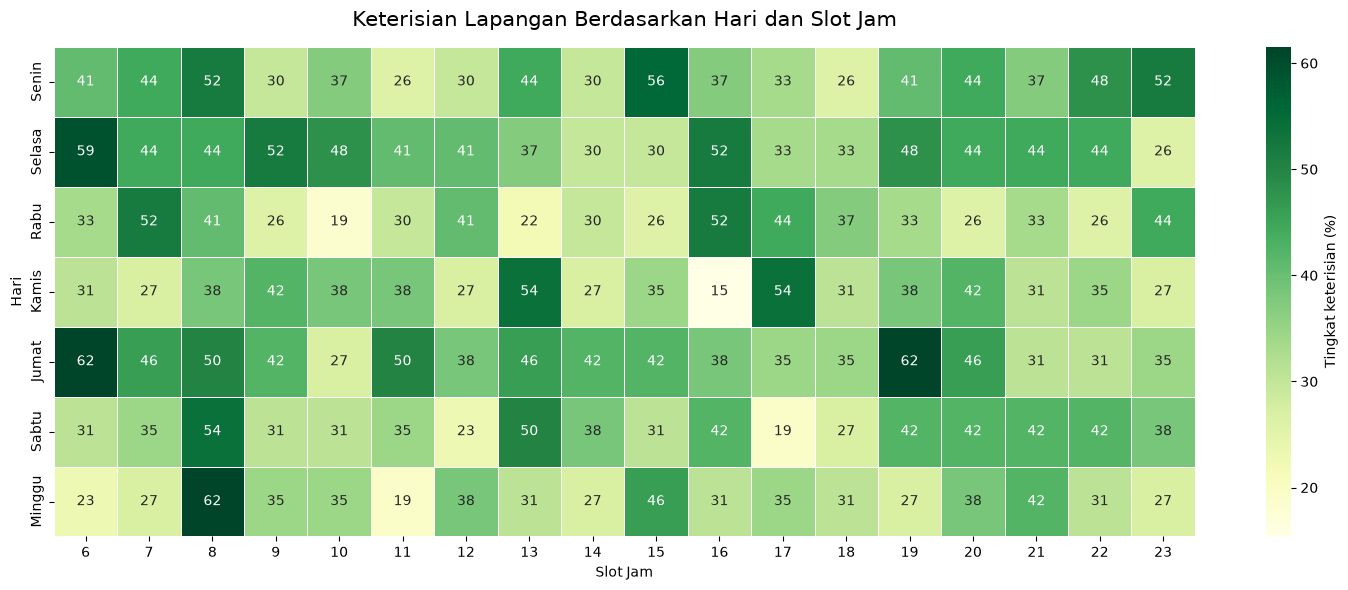

In [45]:
pivot_occ = occupancy_hari_jam.pivot(
    index="hari",
    columns="slot_jam",
    values="tingkat_keterisian"
)

plt.figure(figsize=(15, 6))

sns.heatmap(
    pivot_occ,
    cmap="YlGn",
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={"label": "Tingkat keterisian (%)"}
)

plt.title(
    "Keterisian Lapangan Berdasarkan Hari dan Slot Jam",
    fontsize=15,
    pad=15
)
plt.xlabel("Slot Jam")
plt.ylabel("Hari")
plt.tight_layout()
plt.show()

Cara membaca heatmap:

- Warna hijau tua menunjukkan keterisian tinggi
- Warna hijau muda atau kuning menunjukkan keterisian rendah
- Angka pada kotak menunjukkan persentase slot yang terisi


##### Slot tertinggi dan terendah


In [46]:
occupancy_hari_jam["rentang_jam"] = (
    occupancy_hari_jam["slot_jam"].astype(str).str.zfill(2)
    + ":00-"
    + (occupancy_hari_jam["slot_jam"] + 1)
    .astype(str)
    .str.zfill(2)
    + ":00"
)

top_5 = (
    occupancy_hari_jam
    .sort_values("tingkat_keterisian", ascending=False)
    .head(5)
)

bottom_5 = (
    occupancy_hari_jam
    .sort_values("tingkat_keterisian", ascending=True)
    .head(5)
)

print("5 slot dengan keterisian tertinggi:")
display(top_5[
    ["hari", "rentang_jam", "tingkat_keterisian"]
])

print("5 slot dengan keterisian terendah:")
display(bottom_5[
    ["hari", "rentang_jam", "tingkat_keterisian"]
])

5 slot dengan keterisian tertinggi:


,hari,rentang_jam,tingkat_keterisian
85,Jumat,19:00-20:00,61.538462
72,Jumat,06:00-07:00,61.538462
110,Minggu,08:00-09:00,61.538462
18,Selasa,06:00-07:00,59.259259
9,Senin,15:00-16:00,55.555556


5 slot dengan keterisian terendah:


,hari,rentang_jam,tingkat_keterisian
64,Kamis,16:00-17:00,15.384615
40,Rabu,10:00-11:00,18.518519
101,Sabtu,17:00-18:00,19.230769
113,Minggu,11:00-12:00,19.230769
43,Rabu,13:00-14:00,22.222222


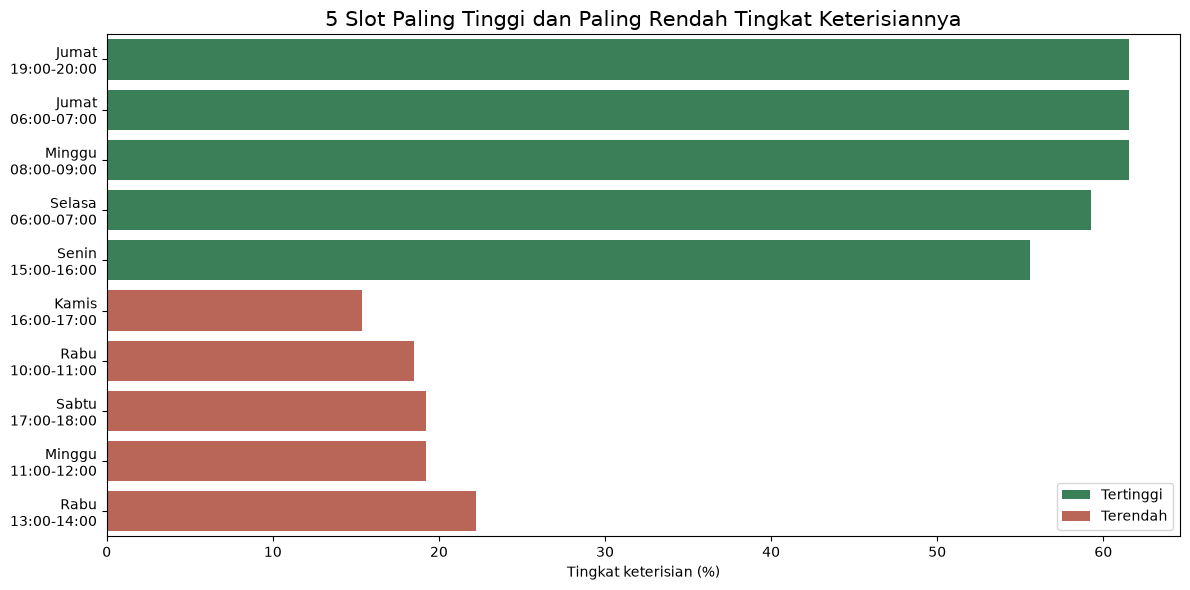

In [47]:
top_bottom = pd.concat([
    top_5.assign(grup="Tertinggi"),
    bottom_5.assign(grup="Terendah")
])

top_bottom["hari_jam"] = (
    top_bottom["hari"].astype(str)
    + "\n"
    + top_bottom["rentang_jam"]
)

plt.figure(figsize=(12, 6))

colors = top_bottom["grup"].map({
    "Tertinggi": "#2E8B57",
    "Terendah": "#C95A49"
})

sns.barplot(
    data=top_bottom,
    x="tingkat_keterisian",
    y="hari_jam",
    hue="grup",
    dodge=False,
    palette={
        "Tertinggi": "#2E8B57",
        "Terendah": "#C95A49"
    }
)

plt.title(
    "5 Slot Paling Tinggi dan Paling Rendah "
    "Tingkat Keterisiannya",
    fontsize=15
)
plt.xlabel("Tingkat keterisian (%)")
plt.ylabel("")
plt.legend(title="")
plt.tight_layout()
plt.show()

#### B. Membandingkan hari kerja, akhir pekan, dan hari libur

In [48]:
def kategori_hari(row):
    if row["is_libur_nasional"] == 1:
        return "Hari libur nasional"
    elif row["is_weekend"] == 1:
        return "Akhir pekan"
    return "Hari kerja"

df_eda["kategori_hari"] = df_eda.apply(
    kategori_hari,
    axis=1
)

In [49]:
urutan_kategori = [
    "Hari kerja",
    "Akhir pekan",
    "Hari libur nasional"
]

ringkasan_kategori = (
    df_eda.groupby("kategori_hari", observed=True)
    .agg(
        tingkat_keterisian=("status_terisi", "mean"),
        jumlah_slot=("status_terisi", "count"),
        jumlah_terisi=("status_terisi", "sum")
    )
    .reset_index()
)

ringkasan_kategori["tingkat_keterisian"] *= 100
ringkasan_kategori["kategori_hari"] = pd.Categorical(
    ringkasan_kategori["kategori_hari"],
    categories=urutan_kategori,
    ordered=True
)

ringkasan_kategori = ringkasan_kategori.sort_values(
    "kategori_hari"
).round({"tingkat_keterisian": 1})

ringkasan_kategori

,kategori_hari,tingkat_keterisian,jumlah_slot,jumlah_terisi
1,Hari kerja,38.4,2358,906
0,Akhir pekan,34.9,918,320
2,Hari libur nasional,40.7,54,22


/tmp/ipykernel_36208/1992085656.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


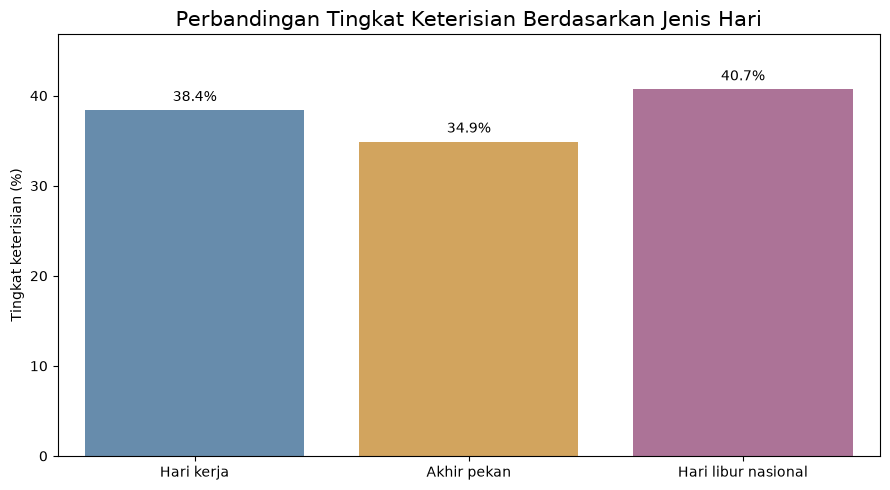

In [50]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=ringkasan_kategori,
    x="kategori_hari",
    y="tingkat_keterisian",
    palette=["#5B8DB8", "#E5A84B", "#B56A9A"]
)

for index, row in ringkasan_kategori.iterrows():
    plt.text(
        x=list(ringkasan_kategori["kategori_hari"]).index(
            row["kategori_hari"]
        ),
        y=row["tingkat_keterisian"] + 1,
        s=f'{row["tingkat_keterisian"]:.1f}%',
        ha="center"
    )

plt.ylim(
    0,
    max(ringkasan_kategori["tingkat_keterisian"]) * 1.15
)
plt.title(
    "Perbandingan Tingkat Keterisian Berdasarkan Jenis Hari",
    fontsize=15
)
plt.xlabel("")
plt.ylabel("Tingkat keterisian (%)")
plt.tight_layout()
plt.show()

##### Keterisian berdasarkan kategori dan rentang jam:

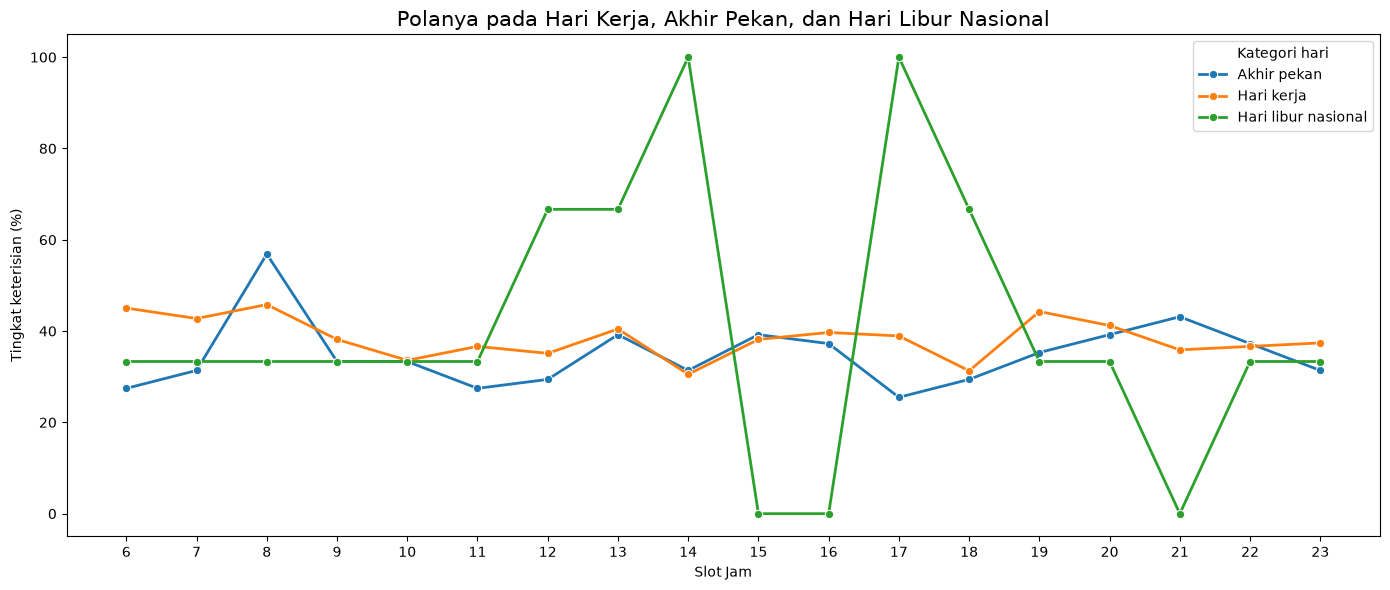

In [51]:
occupancy_kategori_jam = (
    df_eda.groupby(
        ["kategori_hari", "slot_jam"],
        observed=True
    )["status_terisi"]
    .mean()
    .mul(100)
    .rename("tingkat_keterisian")
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=occupancy_kategori_jam,
    x="slot_jam",
    y="tingkat_keterisian",
    hue="kategori_hari",
    marker="o",
    linewidth=2
)

plt.title(
    "Polanya pada Hari Kerja, Akhir Pekan, "
    "dan Hari Libur Nasional",
    fontsize=15
)
plt.xlabel("Slot Jam")
plt.ylabel("Tingkat keterisian (%)")
plt.xticks(sorted(df_eda["slot_jam"].unique()))
plt.legend(title="Kategori hari")
plt.tight_layout()
plt.show()

**Insight:**

Selama periode [tanggal_awal]–[tanggal_akhir], kombinasi hari dan
jam dengan keterisian tertinggi adalah [hari], pukul [jam]. Tingkat
keterisian mencapai [nilai]%.

Sebaliknya, kombinasi terendah adalah [hari], pukul [jam], dengan
tingkat keterisian [nilai]%.

Hari libur nasional memiliki keterisian rata-rata [nilai]%, sedangkan
akhir pekan [nilai]% dan hari kerja [nilai]%. Perbedaan antara akhir
pekan dan hari kerja adalah [selisih] persentase poin.

### Pertanyaan 2:

In [52]:
df_booking = df_eda[
    df_eda["jumlah_booking"] > 0
].copy()

df_booking["kelompok_penggunaan"] = df_booking[
    "jenis_penggunaan"
].replace({
    "futsal": "Futsal",
    "acara": "Acara",
})

In [53]:
proporsi_total = (
    df_booking.groupby("kelompok_penggunaan")
    ["jumlah_booking"]
    .sum()
    .rename("jumlah_booking")
    .reset_index()
)

proporsi_total["proporsi"] = (
    proporsi_total["jumlah_booking"]
    / proporsi_total["jumlah_booking"].sum()
    * 100
).round(1)

proporsi_total

,kelompok_penggunaan,jumlah_booking,proporsi
0,Acara,126,10.1
1,Futsal,1122,89.9


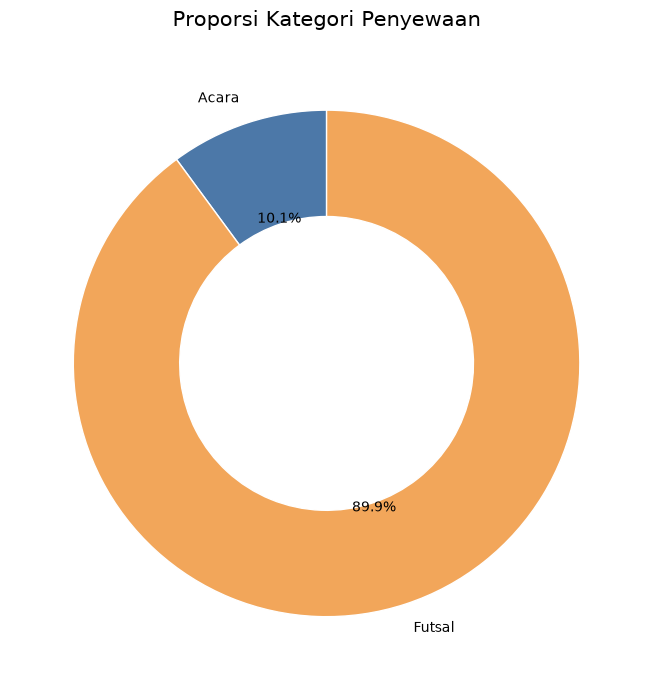

In [54]:
plt.figure(figsize=(7, 7))

plt.pie(
    proporsi_total["jumlah_booking"],
    labels=proporsi_total["kelompok_penggunaan"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C78A8", "#F2A65A"],
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)

plt.title(
    "Proporsi Kategori Penyewaan",
    fontsize=15,
    pad=15
)
plt.tight_layout()
plt.show()

##### Proporsi berdasarkan hari


In [55]:
proporsi_hari = (
    df_booking.groupby(
        ["hari", "kelompok_penggunaan"],
        observed=True
    )["jumlah_booking"]
    .sum()
    .rename("jumlah_booking")
    .reset_index()
)

proporsi_hari["proporsi"] = (
    proporsi_hari["jumlah_booking"]
    / proporsi_hari.groupby(
        "hari",
        observed=True
    )["jumlah_booking"].transform("sum")
    * 100
).round(1)

In [56]:
pivot_proporsi_hari = proporsi_hari.pivot(
    index="hari",
    columns="kelompok_penggunaan",
    values="proporsi"
).fillna(0)

pivot_proporsi_hari

kelompok_penggunaan,Acara,Futsal
hari,,
Senin,18.8,81.2
Selasa,17.7,82.3
Rabu,10.8,89.2
Kamis,0.0,100.0
Jumat,9.1,90.9
Sabtu,10.6,89.4
Minggu,0.0,100.0


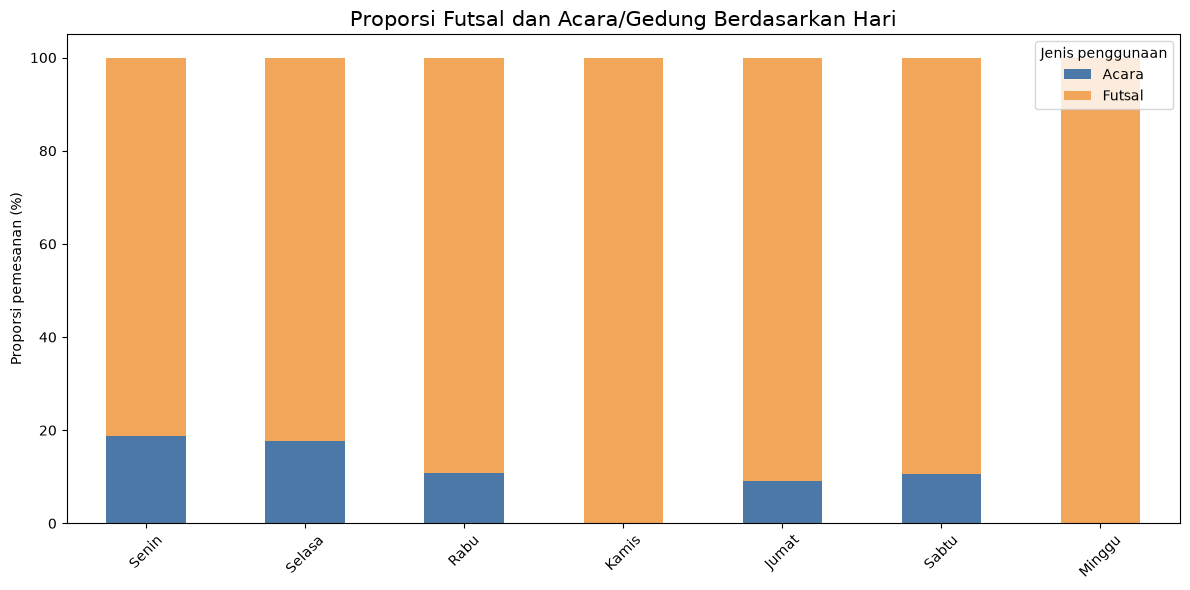

In [57]:
pivot_proporsi_hari.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["#4C78A8", "#F2A65A"]
)

plt.title(
    "Proporsi Futsal dan Acara/Gedung Berdasarkan Hari",
    fontsize=15
)
plt.xlabel("")
plt.ylabel("Proporsi pemesanan (%)")
plt.legend(title="Jenis penggunaan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Proporsi berdasarkan hari dan jam


In [58]:
proporsi_hari_jam = (
    df_booking.groupby(
        ["hari", "slot_jam", "kelompok_penggunaan"],
        observed=True
    )["jumlah_booking"]
    .sum()
    .rename("jumlah_booking")
    .reset_index()
)

proporsi_hari_jam["proporsi"] = (
    proporsi_hari_jam["jumlah_booking"]
    / proporsi_hari_jam.groupby(
        ["hari", "slot_jam"],
        observed=True
    )["jumlah_booking"].transform("sum")
    * 100
).round(1)

pivot_proporsi_jam = proporsi_hari_jam.pivot(
    index="hari",
    columns=["slot_jam", "kelompok_penggunaan"],
    values="proporsi"
).fillna(0)

# menampilkan proporsi pemesanan futsal dan acara/gedung berdasarkan hari dan slot jam


<!-- **Insight:**

Pada periode [tanggal_awal]–[tanggal_akhir], sebanyak
[nilai]% pemesanan berasal dari futsal, sedangkan
[nilai]% berasal dari penyewaan acara atau gedung serbaguna.

Futsal paling dominan pada [hari] pukul [rentang jam],
sedangkan acara atau gedung serbaguna paling banyak digunakan
pada [hari] pukul [rentang jam].

Pada hari kerja, proporsi futsal sebesar [nilai]% dibandingkan
[nilai]% untuk acara. Pada akhir pekan, proporsi tersebut
berubah menjadi [nilai]% dan [nilai]%. -->

Selain musim, kondisi cuaca juga dianalisis untuk mengetahui pengaruhnya terhadap jumlah penyewaan sepeda harian.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1**: Berdasarkan hasil analisis 3–6 bulan terakhir, tingkat keterisian tertinggi terjadi pada hari Senin pukul 14.00 dan hari Selasa jam 15.00 dengan keterisian sekitar 51.851852%, sedangkan keterisian terendah terjadi pada Selasa pukul 17.00 dengan keterisian sekitar 14.814815%. Secara umum, keterisian pada akhir pekan mencapai sekitar 33.9% dan pada hari libur nasional sekitar 33.3%, dibandingkan hari kerja sekitar 36.1%. Pola ini menunjukkan bahwa permintaan berbeda berdasarkan karakteristik hari dan waktu penggunaan.

- Rekomendasi: Prioritaskan pemerataan jadwal operasional dan promosi pada jam dengan keterisian rendah, misalnya melalui harga spesial, paket rutin, atau pengingat kepada pengguna. Pada rentang jam dengan keterisian tinggi, pertimbangkan penambahan slot, pengaturan sistem reservasi yang ketat, dan pengelolaan antrean agar peluang pemesanan tidak terlewatkan.

- **Conclusion pertanyaan 2**: Selama periode 3–6 bulan terakhir, pemesanan futsal rutin memiliki proporsi sekitar 48.9%, sedangkan penyewaan untuk acara atau gedung serbaguna memiliki proporsi sekitar 51.1%. <!--Futsal cenderung paling dominan pada [hari] pukul [rentang jam], sedangkan penyewaan acara atau gedung serbaguna lebih dominan pada [hari] pukul [rentang jam].-->

- Rekomendasi: Pertahankan dan kembangkan penyewaan futsal pada jam dengan permintaan tinggi melalui paket berlangganan mingguan atau kompetisi rutin. Untuk penyewaan acara dan gedung serbaguna, buat paket berdasarkan durasi penggunaan, jumlah peserta, serta kebutuhan pendukung acara. Jadwalkan promosi pada hari dan jam dengan proporsi acara yang masih rendah untuk meningkatkan pemanfaatan fasilitas.

- Kesimpulan tambahan: Keterisian lapangan dipengaruhi oleh kombinasi hari, jam operasional, status akhir pekan, hari libur nasional, dan jenis penggunaan. Analisis per kategori membantu mengidentifikasi waktu yang perlu mendapat perhatian operasional atau pemasaran.

- Rekomendasi tambahan: Jika data yang digunakan masih berupa data dummy, lakukan validasi dengan data pemesanan lapangan yang sebenarnya sebelum menjadikannya dasar keputusan bisnis. Disarankan untuk mencatat tanggal pemesanan, jumlah peserta, jenis kegiatan, durasi penyewaan, status pembayaran, dan sumber data secara konsisten.



**Rekomendasi Action Item:**